# Avaliação e otimização do modelo — Phishing Website Detector
**Módulo 7 do roadmap** · Diogo Carvalho · IAAC — CTeSP Cibersegurança, ISTEC Porto

Este notebook avalia o modelo final guardado em `models/phishing_xgboost.json` (gerado por `models/modeling_phishing.py`).

**Convenção de classes** (igual à de Malware e Ransomware: 1 = ameaça): `0 = Legítimo`, `1 = Phishing`.
A métrica principal é o **Recall de phishing**: um website de phishing classificado como legítimo (falso negativo) é o erro mais grave.

In [1]:
import json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, precision_recall_curve, average_precision_score,
                             classification_report)

warnings.filterwarnings("ignore")
PASTA = Path.cwd().parent
sys.path.insert(0, str(PASTA))
from src.phishing_inference import carregar_modelo, carregar_features

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Reconstruir a divisão 70 / 15 / 15
A mesma semente e a mesma estratificação do `modeling_phishing.py`, para garantir que o teste nunca foi visto durante a seleção.

In [2]:
df = pd.read_csv(PASTA / "dataset" / "phishing_prepared.csv")
features = carregar_features()
X = df[features]
y = (df["class"] == -1).astype(int)   # 1 = Phishing

X_tr, X_rest, y_tr, y_rest = train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)
X_val, X_te, y_val, y_te = train_test_split(X_rest, y_rest, test_size=0.50, random_state=RANDOM_STATE, stratify=y_rest)
print(f"Treino {len(X_tr)} | Validação {len(X_val)} | Teste {len(X_te)}")
print("Phishing por conjunto (%):", [round(float(100 * s.mean()), 1) for s in (y_tr, y_val, y_te)])

Treino 4004 | Validação 858 | Teste 859
Phishing por conjunto (%): [51.6, 51.6, 51.7]


## 2. Comparação dos 8 algoritmos (validação + validação cruzada)

In [3]:
cv = pd.read_csv(PASTA / "models" / "phishing_cv_results.csv")
cv[["Modelo", "Val_Accuracy", "Val_Precision", "Val_Recall", "Val_F1", "Val_ROC_AUC", "CV_Recall_medio", "CV_Recall_std"]]

,Modelo,Val_Accuracy,Val_Precision,Val_Recall,Val_F1,Val_ROC_AUC,CV_Recall_medio,CV_Recall_std
0,Logistic Regression,0.9079,0.9099,0.9120,0.9109,0.9779,0.9352,0.0172
1,k-NN,0.9161,0.9059,0.9345,0.9200,0.9697,0.9391,0.0056
2,Naive Bayes,0.6434,0.5915,1.0000,0.7433,0.9696,0.9995,0.0010
3,SVM (RBF),0.9336,0.9427,0.9278,0.9352,0.9839,0.9439,0.0115
4,Decision Tree,0.9301,0.9246,0.9413,0.9329,0.9791,0.9453,0.0158
5,Random Forest,0.9382,0.9452,0.9345,0.9398,0.9883,0.9449,0.0120
6,Gradient Boosting,0.9441,0.9458,0.9458,0.9458,0.9897,0.9579,0.0093
7,XGBoost,0.9615,0.9702,0.9549,0.9625,0.9939,0.9599,0.0064


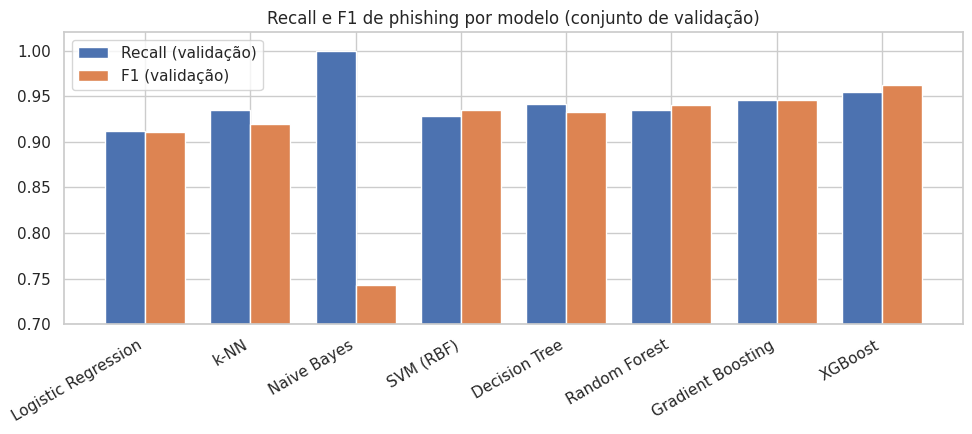

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
idx = np.arange(len(cv)); w = 0.38
ax.bar(idx - w/2, cv["Val_Recall"], w, label="Recall (validação)")
ax.bar(idx + w/2, cv["Val_F1"], w, label="F1 (validação)")
ax.set_xticks(idx); ax.set_xticklabels(cv["Modelo"], rotation=30, ha="right")
ax.set_ylim(0.7, 1.02); ax.set_title("Recall e F1 de phishing por modelo (conjunto de validação)"); ax.legend()
plt.tight_layout(); plt.show()

**Leitura dos resultados**

- O **Naive Bayes** tem Recall de ~100%, mas F1 de ~0,74: prevê quase tudo como phishing, por isso gera muitos falsos positivos. Por isso só concorrem a modelo final os que têm **F1 ≥ 0,90**.
- Os modelos baseados em árvores com *boosting* (**Gradient Boosting** e **XGBoost**) destacam-se dos modelos lineares, do k-NN e do SVM.
- Nenhum modelo apresenta *gap* treino–validação superior a 5%, logo não há sinais fortes de overfitting.

## 3. Modelo final no conjunto de teste (avaliado uma única vez)

In [5]:
modelo = carregar_modelo()
proba = modelo.predict_proba(X_te[features])[:, 1]
pred = (proba >= 0.5).astype(int)

resumo = pd.Series({
    "Accuracy": accuracy_score(y_te, pred), "Precision": precision_score(y_te, pred),
    "Recall": recall_score(y_te, pred), "F1-score": f1_score(y_te, pred),
    "ROC-AUC": roc_auc_score(y_te, proba), "PR-AUC": average_precision_score(y_te, proba),
}).round(4)
print(resumo.to_string())
print()
print(classification_report(y_te, pred, target_names=["Legítimo (0)", "Phishing (1)"]))

Accuracy     0.9593
Precision    0.9637
Recall       0.9572
F1-score     0.9605
ROC-AUC      0.9928
PR-AUC       0.9941

              precision    recall  f1-score   support

Legítimo (0)       0.95      0.96      0.96       415
Phishing (1)       0.96      0.96      0.96       444

    accuracy                           0.96       859
   macro avg       0.96      0.96      0.96       859
weighted avg       0.96      0.96      0.96       859



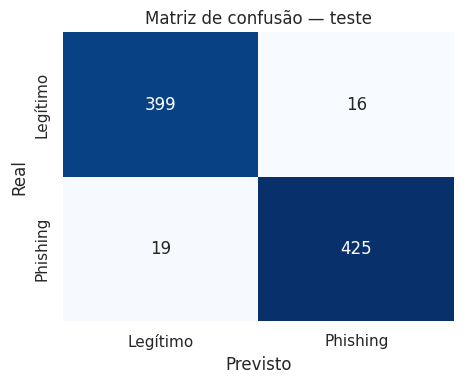

Falsos negativos (phishing não detetado): 19 | Falsos positivos (legítimo marcado como phishing): 16


In [6]:
mat = confusion_matrix(y_te, pred)
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(mat, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Legítimo", "Phishing"], yticklabels=["Legítimo", "Phishing"])
ax.set_xlabel("Previsto"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusão — teste")
plt.tight_layout(); plt.show()
print(f"Falsos negativos (phishing não detetado): {mat[1,0]} | Falsos positivos (legítimo marcado como phishing): {mat[0,1]}")

## 4. Curvas ROC e Precision–Recall

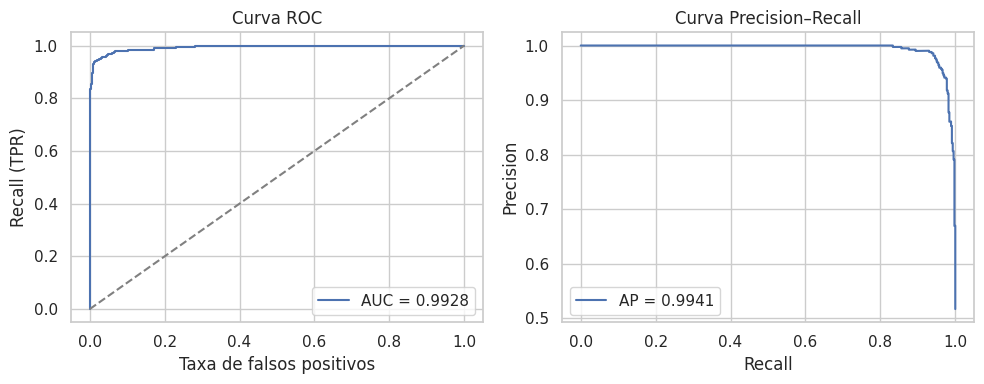

In [7]:
fpr, tpr, _ = roc_curve(y_te, proba)
prec, rec, _ = precision_recall_curve(y_te, proba)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_te, proba):.4f}"); axs[0].plot([0, 1], [0, 1], "--", color="grey")
axs[0].set_xlabel("Taxa de falsos positivos"); axs[0].set_ylabel("Recall (TPR)"); axs[0].set_title("Curva ROC"); axs[0].legend()
axs[1].plot(rec, prec, label=f"AP = {average_precision_score(y_te, proba):.4f}")
axs[1].set_xlabel("Recall"); axs[1].set_ylabel("Precision"); axs[1].set_title("Curva Precision–Recall"); axs[1].legend()
plt.tight_layout(); plt.show()

## 5. Overfitting: treino vs validação vs teste

In [8]:
acc = {nome: accuracy_score(yy, modelo.predict(XX[features])) for nome, XX, yy in
       [("Treino", X_tr, y_tr), ("Validação", X_val, y_val), ("Teste", X_te, y_te)]}
print({k: round(v, 4) for k, v in acc.items()})
print(f"Gap treino–teste: {acc['Treino'] - acc['Teste']:+.4f}")

{'Treino': 0.9878, 'Validação': 0.9604, 'Teste': 0.9593}
Gap treino–teste: +0.0285


## 6. Limiar de decisão (threshold)
Por omissão classifica-se como phishing quando `P(phishing) ≥ 0,5`. Num contexto de segurança, pode justificar-se **baixar o limiar** para apanhar mais phishing, à custa de mais falsos positivos.

In [9]:
linhas = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba >= t).astype(int)
    linhas.append({"Limiar": t, "Recall": recall_score(y_te, p), "Precision": precision_score(y_te, p),
                   "F1": f1_score(y_te, p), "Falsos negativos": int(((p == 0) & (y_te == 1)).sum()),
                   "Falsos positivos": int(((p == 1) & (y_te == 0)).sum())})
pd.DataFrame(linhas).round(4)

,Limiar,Recall,Precision,F1,Falsos negativos,Falsos positivos
0,0.2,0.9775,0.9254,0.9507,10,35
1,0.3,0.9707,0.9452,0.9578,13,25
2,0.4,0.9640,0.9554,0.9596,16,20
3,0.5,0.9572,0.9637,0.9605,19,16
4,0.6,0.9459,0.9813,0.9633,24,8
5,0.7,0.9279,0.9904,0.9581,32,4


## 7. Importância das features

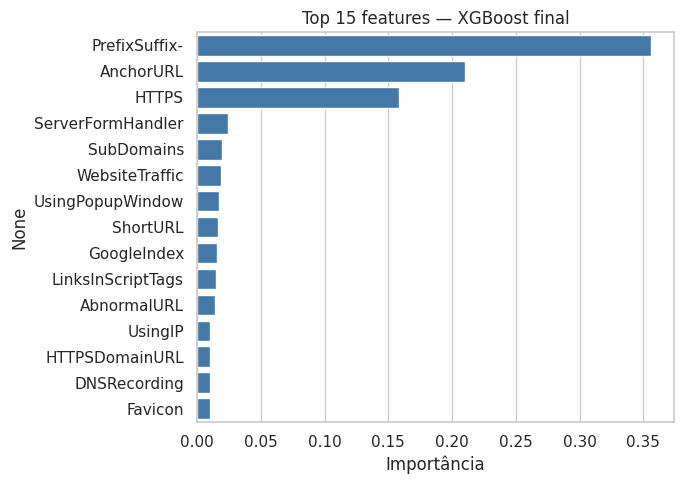

In [10]:
imp = pd.Series(modelo.feature_importances_, index=features).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(x=imp.values, y=imp.index, color="#337AB7", ax=ax)
ax.set_title("Top 15 features — XGBoost final"); ax.set_xlabel("Importância")
plt.tight_layout(); plt.show()

**Interpretação:** `PrefixSuffix-` (hífen no domínio), `AnchorURL` (proporção de âncoras que apontam para outro domínio) e `HTTPS` concentram a maior parte da importância. Estas três features dominam o modelo, o que é coerente com a literatura sobre phishing, mas também significa que o modelo depende muito de poucas características.

## 8. Explicação de uma previsão individual (contribuições SHAP do XGBoost)

In [11]:
from src.phishing_inference import prever_phishing
amostra = X_te[features].iloc[0].to_dict()
r = prever_phishing(amostra)
print("Real:", "Phishing" if y_te.iloc[0] == 1 else "Legítimo", "| Previsto:", r["classificacao"], f"({r['confianca']:.1%})")
for f in r["top_features"]:
    sentido = "→ phishing" if f["contribuicao"] > 0 else "→ legítimo"
    print(f"  {f['feature']:<20} valor={f['valor']:>4.0f}  contribuição={f['contribuicao']:+.2f} {sentido}")

Real: Legítimo | Previsto: Legítimo (86.2%)
  HTTPS                valor=   1  contribuição=-1.80 → legítimo
  WebsiteTraffic       valor=   0  contribuição=+1.60 → phishing
  AbnormalURL          valor=  -1  contribuição=-1.36 → legítimo
  Redirecting//        valor=  -1  contribuição=+0.98 → phishing
  LinksPointingToPage  valor=   1  contribuição=-0.88 → legítimo


## 9. Conclusões e limitações

- O XGBoost otimizado atinge no teste **Accuracy ≈ 95,9%**, **Recall ≈ 95,7%** e **ROC-AUC ≈ 0,993**, com validação cruzada consistente.
- Foi escolhido por maximizar o Recall de phishing na validação, entre os modelos com F1 aceitável.
- O dataset foi limpo de duplicados e de perfis contraditórios (5.721 registos); os resultados **não** garantem desempenho em campanhas novas.
- As features já vêm extraídas e codificadas (-1, 0, 1): o sistema **não** visita URLs nem analisa websites em tempo real.
- O limiar de decisão pode ser ajustado conforme o custo relativo de falsos negativos e falsos positivos.